# 01 · ¿Podemos confiar en los datos?

> **Reto 2 del INE:** "¿Qué zonas podrían presentar mayor abstención en el futuro si no se interviene?"
>
> Vamos a estimar el riesgo de cada municipio para la elección de 2027 a partir de cómo ha votado entre 2009 y 2024.

**La pregunta de este notebook:** ¿la participación que calculamos para cada municipio en cada elección es confiable? Si no lo es, el semáforo marcaría en rojo a municipios por errores de los datos y no por baja participación.

## Resumen de lo que encontramos

1. **Los datos están bien construidos.** Según la validación del proceso de preparación (`scripts.prepare_data`), los conteos cuadran (lista = votó + no votó + no sabemos) en las 54.9 millones de filas, y no hay filas duplicadas.
2. **Hay "no sabemos" (NS).** En pocos municipios es tanto que su participación no es confiable. Regla: si no sabemos lo que hizo más de la mitad de la lista, ese año se marca como "sin dato".
3. **En 2012 faltan partes de la lista sin aviso.** Hay que revisarlo con otra regla.
4. **Hay pocos valores raros:** tres municipios con 0 votos en 2012, participación sospechosamente alta en Guerrero en 2024 y personas de hasta 140 años. Casi no cambian los resultados, pero hay que decidir qué hacer con ellos.
5. **Paracho y Parácuaro vienen cruzados en 2021.** Ya está corregido aquí.
6. **Pistas para el modelo:**
   - Los que menos votan son los hombres de 20 a 29 años.
   - La elección más reciente predice mejor cómo votará cada municipio.

Al final hay una tabla con **8 decisiones** y mi recomendación para cada una.

## Las palabras que se usan

| Término | Qué significa |
|---|---|
| **Lista nominal (LN)** | Personas registradas para votar en esa sección. |
| **Votó (SV)** | Su nombre aparece marcado en el cuadernillo de la casilla. |
| **No votó (NV)** | Su nombre aparece sin marca. |
| **No sabemos (NS)** | Cuadernillo perdido, que no se pudo capturar o con páginas faltantes. Es **falta de información, no abstención**. |
| **Participación** | Votaron entre los que sabemos qué hicieron. Es la fórmula oficial del INE (manual, p. 17). |
| **cvegeo** | Clave del municipio según el INEGI. Es la que usamos para seguir a un municipio en el tiempo y para dibujar el mapa. |
| **pp (puntos porcentuales)** | Diferencia entre dos porcentajes: de 50 % a 55 % son 5 pp. |

$$\text{Participación} = \frac{\text{Votó}}{\text{Votó} + \text{No votó}}$$

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(12)
pl.Config.set_fmt_str_lengths(40)
pl.Config.set_tbl_width_chars(160)

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file() and (p / 'data').is_dir())
datos = pl.scan_parquet(raiz / 'data/processed/ccpc/ccpc-*.parquet')
ANIOS = [2009, 2012, 2015, 2018, 2021, 2024]
TIPO = {2009: 'intermedia', 2012: 'presidencial', 2015: 'intermedia', 2018: 'presidencial', 2021: 'intermedia', 2024: 'presidencial'}

# Clave INEGI de cada municipio por año (tabla de equivalencias de Jorge)
equivalencias = pl.read_csv(raiz / 'data/reference/equivalencias_ine_inegi.csv', infer_schema=False).select(
    pl.col('anio').cast(pl.Int16).alias('AELEC'),
    pl.col('cve_ent_ine').cast(pl.Int8).alias('EDOCVE'),
    pl.col('cve_mun_ine').cast(pl.Int16).alias('MPIOCVE'),
    'cvegeo',
)
# Corrección (ver sección 5): en 2021 vienen cruzados los nombres de Paracho y Parácuaro
equivalencias = equivalencias.with_columns(
    cvegeo=pl.when((pl.col('AELEC') == 2021) & (pl.col('EDOCVE') == 16) & (pl.col('MPIOCVE') == 65)).then(pl.lit('16064'))
    .when((pl.col('AELEC') == 2021) & (pl.col('EDOCVE') == 16) & (pl.col('MPIOCVE') == 66)).then(pl.lit('16065'))
    .otherwise(pl.col('cvegeo'))
)
estados = datos.filter(pl.col('AELEC') == 2024).group_by('EDOCVE').agg(estado=pl.col('EDONOM').first()).collect()

# Una fila por municipio y elección
municipios = (
    datos.group_by('AELEC', 'EDOCVE', 'MPIOCVE')
    .agg(pl.col('MPIONOM').first().alias('municipio'), pl.col('LN', 'SV', 'NV', 'NS').sum())
    .collect()
    .join(equivalencias, on=['AELEC', 'EDOCVE', 'MPIOCVE'], validate='1:1')
    .join(estados, on='EDOCVE')
    .with_columns(
        pct_no_sabemos=pl.col('NS') / pl.col('LN') * 100,
        # Solo se calcula si hay alguien con dato (evita dividir 0 entre 0)
        participacion=pl.when(pl.col('SV') + pl.col('NV') > 0).then(pl.col('SV') / (pl.col('SV') + pl.col('NV')) * 100),
    )
)
print(f'Filas leídas: {datos.select(pl.len()).collect().item():,} · municipio-elección: {municipios.height:,}')

Filas leídas: 54,872,712 · municipio-elección: 14,779


## 1 · Los datos en una mirada

**Qué son:** los Conteos Censales de Participación Ciudadana del INE. Dicen, a partir de los cuadernillos de las casillas, cuántas personas votaron y cuántas no, en cada elección federal de 2009 a 2024.

**Qué representa cada fila:** una combinación de elección, sección, sexo y edad. Por ejemplo, "mujeres de 23 años de la sección 1234 de Puebla en 2021". No hay datos de personas individuales.

**Lo que no incluyen** (diccionario de datos):

- **Voto en casillas especiales.**
- **Voto desde el extranjero.**
- **La sección es la del domicilio de la credencial**, no la casilla donde se votó.

Por eso nuestras cifras **pueden diferir de los resultados oficiales** (los cómputos), y hay que decirlo en el reporte.

In [2]:
nacional = (
    datos.group_by('AELEC').agg(pl.col('LN', 'SV', 'NV', 'NS').sum()).collect().sort('AELEC')
    .select(
        pl.col('AELEC').alias('Elección'),
        pl.col('AELEC').replace_strict(TIPO, return_dtype=pl.String).alias('Tipo'),
        pl.col('LN').alias('Lista nominal'),
        (pl.col('SV') / (pl.col('SV') + pl.col('NV')) * 100).round(2).alias('Participación oficial (%)'),
        (pl.col('SV') / pl.col('LN') * 100).round(2).alias('Si contáramos "no sabemos" como "no votó" (%)'),
        (pl.col('NS') / pl.col('LN') * 100).round(2).alias('No sabemos (% de la lista)'),
    )
)
nacional

Elección,Tipo,Lista nominal,Participación oficial (%),"Si contáramos ""no sabemos"" como ""no votó"" (%)",No sabemos (% de la lista)
i16,str,i64,f64,f64,f64
2009,"""intermedia""",77481831,44.06,43.0,2.41
2012,"""presidencial""",76490962,62.08,61.95,0.22
2015,"""intermedia""",83563462,47.07,44.19,6.13
2018,"""presidencial""",89123997,62.37,58.1,6.83
2021,"""intermedia""",93532133,51.84,49.6,4.32
2024,"""presidencial""",98330348,59.67,55.83,6.43


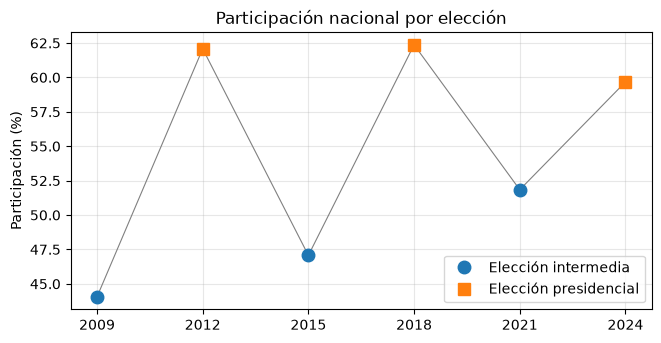

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(nacional['Elección'], nacional['Participación oficial (%)'], color='gray', linewidth=0.8)
for tipo, marca in [('intermedia', 'o'), ('presidencial', 's')]:
    d = nacional.filter(pl.col('Tipo') == tipo)
    ax.plot(d['Elección'], d['Participación oficial (%)'], marca, markersize=9, label=f'Elección {tipo}')
ax.set_xticks(ANIOS)
ax.set_ylabel('Participación (%)')
ax.set_title('Participación nacional por elección')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Qué vemos:**

- **Las presidenciales siempre tienen más participación** que las intermedias.
- **Las intermedias van subiendo:** 44.06 % en 2009, 47.07 % en 2015 y 51.84 % en 2021.

**Qué significa para el reto:**

- **2027 es intermedia**, así que su nivel nacional se parecerá más al de 2021 que al de 2024.
- Con solo tres intermedias **no se puede predecir con confianza el nivel nacional de 2027**. Por eso lo vamos a manejar como escenarios (bajo, medio y alto), y el modelo se va a concentrar en **qué municipios quedan por debajo del resto**.

## 2 · Los "no sabemos" (NS)

### Por qué importan, con un ejemplo

Un municipio tiene 1,000 personas en la lista: 500 votaron, 300 no votaron y de 200 no sabemos porque se perdió un cuadernillo.

| Forma de calcular | Resultado |
|---|---|
| Contar a los 200 como "no votó": 500 / 1,000 | **50 %** |
| Dejarlos fuera, como hace el INE: 500 / 800 | **62.5 %** |

Con la primera forma, el municipio **parece abstencionista solo porque se perdieron papeles**. Por eso usamos la fórmula del INE.

**Pero si no sabemos lo que hizo la mayoría, la cifra deja de ser confiable.** Si de 1,000 personas solo sabemos lo que hicieron 100, la participación depende de esas 100. Por eso necesitamos un límite.

### ¿Cuánto "no sabemos" hay?

In [4]:
municipios.group_by('AELEC').agg(
    pl.len().alias('Municipios'),
    (pl.col('pct_no_sabemos') > 50).sum().alias('Municipios donde no sabemos lo de más de la mitad'),
    (pl.col('LN').filter(pl.col('pct_no_sabemos') > 50).sum() / pl.col('LN').sum() * 100).round(2).alias('Personas que viven ahí (% del país)'),
).sort('AELEC').rename({'AELEC': 'Elección'})

Elección,Municipios,Municipios donde no sabemos lo de más de la mitad,Personas que viven ahí (% del país)
i16,u32,u32,f64
2009,2458,16,0.32
2012,2455,3,0.03
2015,2458,67,0.97
2018,2463,56,0.85
2021,2468,26,0.27
2024,2477,38,0.34


**Qué vemos:**

- En cada elección hay **entre 3 y 67 municipios** donde no sabemos lo que hizo más de la mitad de la lista.
- Ahí vive **menos del 1 % de las personas del país**.

**Qué significa:** es un problema de pocos municipios, no del país. Pero el semáforo es municipio por municipio, así que **esos municipios necesitan un trato especial**: no tienen dato confiable ese año.

### ¿Los municipios con huecos votan distinto?

Si los datos faltaran justo en los municipios que votan poco, estaríamos escondiendo el problema que el reto quiere encontrar. Para saberlo, se comparan los municipios que **alguna vez** tuvieron más de la mitad sin dato con los que nunca, usando solo las elecciones en que **sí** hay buen dato.

In [5]:
con_huecos = municipios.filter(pl.col('pct_no_sabemos') > 50).select('cvegeo').unique().with_columns(grupo=pl.lit('Alguna vez con más de la mitad sin dato'))
(
    municipios.join(con_huecos, on='cvegeo', how='left')
    .with_columns(pl.col('grupo').fill_null('Nunca'))
    .filter(pl.col('pct_no_sabemos') <= 50)
    .group_by('AELEC', 'grupo').agg(pl.col('participacion').median().round(1))
    .pivot(on='grupo', index='AELEC', values='participacion').sort('AELEC')
    .rename({'AELEC': 'Elección'})
)

Elección,Nunca,Alguna vez con más de la mitad sin dato
i16,f64,f64
2009,45.3,45.6
2012,64.0,64.1
2015,50.8,52.5
2018,66.5,68.4
2021,61.2,62.0
2024,62.3,60.9


**Qué vemos:** en sus elecciones con buen dato, los dos grupos tienen una participación típica (la mediana) muy parecida, con menos de 2 pp de diferencia.

**Qué significa:** **los huecos no se concentran en los municipios que votan poco.** Marcar esos años como "sin dato" no esconde el riesgo.

### Municipios donde siempre falta información

Hay municipios donde el problema se repite elección tras elección.

In [6]:
(
    municipios.filter(pl.col('pct_no_sabemos') > 50)
    .group_by('cvegeo').agg(pl.col('estado').last(), pl.col('municipio').last(), pl.col('AELEC').sort().alias('Elecciones con más de la mitad sin dato'), pl.len().alias('Cuántas'))
    .filter(pl.col('Cuántas') >= 2).sort('Cuántas', descending=True)
)

cvegeo,estado,municipio,Elecciones con más de la mitad sin dato,Cuántas
str,str,str,list[i16],u32
"""16024""","""MICHOACAN""","""Cherán""","[2015, 2018, … 2024]",4
"""20248""","""OAXACA""","""San Mateo del Mar""","[2012, 2021, 2024]",3
"""07121""","""CHIAPAS""","""Rincón Chamula San Pedro""","[2018, 2024]",2
"""20472""","""OAXACA""","""Santiago Laollaga""","[2021, 2024]",2
"""20357""","""OAXACA""","""Santa Ana Tavela""","[2018, 2024]",2
"""14019""","""JALISCO""","""Bolaños""","[2018, 2021]",2
"""16056""","""MICHOACAN""","""Nahuatzen""","[2018, 2024]",2
"""31103""","""YUCATAN""","""Xocchel""","[2018, 2021]",2
"""20048""","""OAXACA""","""Magdalena Mixtepec""","[2015, 2024]",2


**Qué vemos:** 9 municipios. El más claro es **Cherán (Michoacán)**: en las cuatro elecciones de 2015 a 2024 no sabemos lo que hizo entre el 84 % y el 89 % de su lista.

**Qué significa:** cuando falta información **siempre**, puede no ser un accidente. **Hipótesis por verificar:** casillas que no se instalan o una comunidad que no participa en la elección federal (Cherán se rige por autogobierno).

**Recomendación:** no ponerlos en el mismo gris que un dato perdido una sola vez. Conviene una marca propia en el mapa: "sin registro en varias elecciones".

### El problema escondido de 2012

En 2012 casi no hay "no sabemos" (0.22 %). Parecería el mejor año, pero no lo es: **ese año faltan partes de la lista sin que quedaran registradas como NS**.

In [7]:
seccion_lista = datos.group_by('AELEC', 'EDOCVE', 'SECCION').agg(pl.col('LN').sum()).collect()
clave = ['EDOCVE', 'SECCION']
filas = []
for antes, anio, despues in zip(ANIOS, ANIOS[1:], ANIOS[2:]):
    a = seccion_lista.filter(pl.col('AELEC') == antes).select(*clave)
    t = seccion_lista.filter(pl.col('AELEC') == anio).select(*clave)
    d = seccion_lista.filter(pl.col('AELEC') == despues).select(*clave)
    filas.append({'Elección': anio, f'Secciones que existen antes y después, pero no en esta elección': a.join(d, on=clave).join(t, on=clave, how='anti').height})
print(pl.DataFrame(filas))

lista_mpio = municipios.pivot(on='AELEC', index='cvegeo', values='LN')
cayeron = lista_mpio.filter(pl.col('2012') < 0.8 * (pl.col('2009') + pl.col('2015')) / 2)
print(f'Municipios cuya lista en 2012 es menor al 80 % de la de 2009 y 2015: {cayeron.height}')
cayeron.join(municipios.filter(pl.col('AELEC') == 2012).select('cvegeo', 'estado', 'municipio'), on='cvegeo').select(
    'estado', 'municipio', pl.col('2009').alias('Lista 2009'), pl.col('2012').alias('Lista 2012'), pl.col('2015').alias('Lista 2015')
).sort(pl.col('Lista 2012') / pl.col('Lista 2009')).head(8)

shape: (4, 2)
┌──────────┬───────────────────────────────────────────┐
│ Elección ┆ Secciones que existen antes y después, p… │
│ ---      ┆ ---                                       │
│ i64      ┆ i64                                       │
╞══════════╪═══════════════════════════════════════════╡
│ 2012     ┆ 1048                                      │
│ 2015     ┆ 0                                         │
│ 2018     ┆ 0                                         │
│ 2021     ┆ 0                                         │
└──────────┴───────────────────────────────────────────┘
Municipios cuya lista en 2012 es menor al 80 % de la de 2009 y 2015: 109


estado,municipio,Lista 2009,Lista 2012,Lista 2015
str,str,i64,i64,i64
"""MICHOACAN""","""Cherán""",12845,1812,12619
"""OAXACA""","""San Pedro Coxcaltepec Cántaros""",624,126,596
"""CHIHUAHUA""","""Rosario""",2260,515,1983
"""CHIHUAHUA""","""Balleza""",12293,3217,12410
"""TAMAULIPAS""","""Guerrero""",3642,1441,2653
"""CHIHUAHUA""","""Julimes""",4805,1939,4572
"""YUCATAN""","""Dzitás""",2488,1107,2725
"""SONORA""","""Arizpe""",2801,1253,2846


**Qué vemos:**

- **1,048 secciones** existen en 2009 y en 2015, pero **no aparecen en 2012**. En ninguna otra elección pasa algo así.
- **109 municipios** tienen en 2012 una lista mucho menor que en 2009 y 2015. Cherán, por ejemplo, tiene 1,812 personas en 2012, contra 12,845 en 2009 y 12,619 en 2015.

**Qué significa:** en 2012 los cuadernillos faltantes **se quitaron de la lista** en lugar de marcarse como "no sabemos". La regla del NS no los detecta.

**Recomendación:**

- Agregar una segunda regla: si la lista de un municipio en un año es menor al 80 % de la de sus elecciones vecinas, ese año también es "sin dato".
- Como 2012 fue presidencial y 2027 será intermedia, el modelo puede darle poco peso a ese año.

## 3 · Municipios sin ningún dato

En algunos casos **no hay ni un solo registro** de quién votó en todo el municipio.

In [8]:
sin_ningun_dato = municipios.filter(pl.col('SV') + pl.col('NV') == 0)
print(f'Municipio-elección sin ningún dato: {sin_ningun_dato.height} · de ellos en Oaxaca: {sin_ningun_dato.filter(pl.col("estado") == "OAXACA").height}')
sin_ningun_dato.group_by('AELEC').len().sort('AELEC').rename({'AELEC': 'Elección', 'len': 'Municipios sin ningún dato'})

Municipio-elección sin ningún dato: 73 · de ellos en Oaxaca: 44


Elección,Municipios sin ningún dato
i16,u32
2009,7
2012,1
2015,30
2018,13
2021,10
2024,12


**Qué vemos:** 73 casos en total, 44 de ellos en Oaxaca.

**Cuidado técnico:** su participación sería 0 / 0. Según la herramienta, eso aparece como 0 %, como vacío o como un valor que se ordena como el más alto. **Nunca debe aparecer como 0 %**, porque se pintaría de rojo.

**Recomendación:** marcarlos como "sin dato" en esa elección. Si se repite en varias elecciones, usar la marca de "sin registro en varias elecciones" de la sección 2.

## 4 · Valores raros

### Personas de hasta 140 años

La lista tiene personas registradas con edades de hasta 140 años. Antes de decidir qué hacer, hay que medir cuántas son y si cambian algo.

In [9]:
mayores = (
    datos.filter(pl.col('AELEC') == 2024)
    .with_columns(grupo=pl.when(pl.col('EDAD') < 100).then(pl.lit('Menos de 100 años')).when(pl.col('EDAD') < 110).then(pl.lit('100 a 109 años')).otherwise(pl.lit('110 años o más')))
    .group_by('grupo').agg(pl.col('LN', 'SV', 'NV').sum(), pl.col('EDAD').max().alias('Edad máxima'))
    .collect()
    .select(
        pl.col('grupo').alias('Grupo (2024)'),
        pl.col('LN').alias('Personas en la lista'),
        (pl.col('LN') / pl.col('LN').sum() * 100).round(3).alias('% de la lista'),
        (pl.col('SV') / (pl.col('SV') + pl.col('NV')) * 100).round(1).alias('Participación (%)'),
        'Edad máxima',
    )
)
mayores

Grupo (2024),Personas en la lista,% de la lista,Participación (%),Edad máxima
str,i64,f64,f64,i16
"""100 a 109 años""",19467,0.02,18.4,109
"""110 años o más""",298,0.0,26.1,140
"""Menos de 100 años""",98310583,99.98,59.7,99


In [10]:
# ¿Cuánto cambia la participación de cada municipio si quitamos a las personas de 100 años o más?
for anio in [2009, 2024]:
    sin_100 = datos.filter((pl.col('AELEC') == anio) & (pl.col('EDAD') < 100)).group_by('EDOCVE', 'MPIOCVE').agg(pl.col('SV', 'NV').sum()).collect()
    cambio = (
        municipios.filter(pl.col('AELEC') == anio).join(sin_100.rename({'SV': 'SV2', 'NV': 'NV2'}), on=['EDOCVE', 'MPIOCVE'])
        .filter(pl.col('SV2') + pl.col('NV2') > 0)
        .with_columns(cambio=(pl.col('SV2') / (pl.col('SV2') + pl.col('NV2')) * 100 - pl.col('participacion')).abs())
    )
    print(f'{anio}: el municipio que más cambia, cambia {cambio["cambio"].max():.2f} pp')

2009: el municipio que más cambia, cambia 1.90 pp
2024: el municipio que más cambia, cambia 0.39 pp


**Qué vemos:**

- **Cuántas son:** en 2024 hay 19,765 personas de 100 años o más, alrededor del 0.02 % de la lista. Votan mucho menos: 18 % a 26 %.
- **Dónde están:** dispersas por todo el país, casi una por sección. No es un error concentrado en un lugar. Esto se verificó en la versión anterior de este análisis: las de 110 años o más aparecen en 26 a 32 estados, con un máximo de 7 personas en una misma combinación de sección, sexo y edad.
- **Cuánto cambian el resultado:** quitarlas mueve la participación de un municipio como máximo 0.39 pp en 2024 y 1.9 pp en 2009.

**Qué significa:** **probablemente son registros con fecha de nacimiento equivocada o de personas que ya fallecieron. Es una hipótesis.** Como son tan pocas, casi no afectan a los municipios.

**Recomendación:**

- **Totales:** no quitarlas. Así se respeta la lista oficial y el efecto es mínimo.
- **Gráficas por edad:** agruparlas en "100 y más", como hace el propio INE.

### Municipios con participación muy baja o muy alta

In [11]:
otros_anios = municipios.select('cvegeo', pl.col('AELEC').alias('otro'), pl.col('participacion').alias('p_otro'))
def con_su_historia(tabla):
    return (
        tabla.join(otros_anios, on='cvegeo').filter(pl.col('otro') != pl.col('AELEC'))
        .group_by('AELEC', 'estado', 'municipio', 'LN', 'participacion')
        .agg(pl.col('p_otro').median().alias('Participación típica en sus otras elecciones (%)'))
        .select(pl.col('AELEC').alias('Elección'), 'estado', 'municipio', pl.col('LN').alias('Lista'),
                pl.col('participacion').round(1).alias('Participación (%)'), pl.col('Participación típica en sus otras elecciones (%)').round(1))
    )

print('Participación menor a 2 % (casi nadie votó):')
print(con_su_historia(municipios.filter(pl.col('participacion') < 2)).sort('Participación (%)'))
print()
print('Participación mayor a 90 %, fuera de Yucatán:')
print(con_su_historia(municipios.filter((pl.col('participacion') > 90) & (pl.col('estado') != 'YUCATAN'))).sort('Elección'))

Participación menor a 2 % (casi nadie votó):
shape: (5, 6)
┌──────────┬────────┬──────────────────────────┬───────┬───────────────────┬───────────────────────────────────────────┐
│ Elección ┆ estado ┆ municipio                ┆ Lista ┆ Participación (%) ┆ Participación típica en sus otras elecci… │
│ ---      ┆ ---    ┆ ---                      ┆ ---   ┆ ---               ┆ ---                                       │
│ i16      ┆ str    ┆ str                      ┆ i64   ┆ f64               ┆ f64                                       │
╞══════════╪════════╪══════════════════════════╪═══════╪═══════════════════╪═══════════════════════════════════════════╡
│ 2012     ┆ OAXACA ┆ San Mateo Sindihui       ┆ 1400  ┆ 0.0               ┆ 39.5                                      │
│ 2012     ┆ OAXACA ┆ San Miguel Piedras       ┆ 829   ┆ 0.0               ┆ 51.9                                      │
│ 2012     ┆ OAXACA ┆ San Pedro Teozacoalco    ┆ 421   ┆ 0.0               ┆ 51.2             

In [12]:
# Yucatán: ¿sus municipios arriba de 90 % son raros o es un estado que vota mucho?
estatal = municipios.group_by('AELEC', 'estado').agg((pl.col('SV').sum() / (pl.col('SV').sum() + pl.col('NV').sum()) * 100).alias('p'))
estatal.with_columns(pl.col('p').rank(descending=True).over('AELEC').cast(pl.Int8).alias('Lugar entre 32 estados')).filter(pl.col('estado') == 'YUCATAN').select(
    pl.col('AELEC').alias('Elección'), pl.col('p').round(1).alias('Participación de Yucatán (%)'), 'Lugar entre 32 estados'
).sort('Elección')

Elección,Participación de Yucatán (%),Lugar entre 32 estados
i16,f64,i8
2009,55.7,4
2012,76.8,1
2015,70.6,1
2018,74.5,1
2021,63.1,2
2024,71.4,1


In [13]:
# Secciones con 95 % o más de participación (y al menos 100 personas con dato), por estado
secciones = (
    datos.group_by('AELEC', 'EDOCVE', 'SECCION').agg(pl.col('SV', 'NV').sum())
    .filter(pl.col('SV') + pl.col('NV') >= 100).collect().join(estados, on='EDOCVE')
    .filter(pl.col('SV') / (pl.col('SV') + pl.col('NV')) >= 0.95)
)
secciones.group_by('estado', 'AELEC').len().pivot(on='AELEC', index='estado', values='len', sort_columns=True).fill_null(0).filter(
    pl.col('estado').is_in(['GUERRERO', 'CHIAPAS', 'YUCATAN'])
)

estado,2009,2012,2015,2018,2021,2024
str,u32,u32,u32,u32,u32,u32
"""GUERRERO""",0,2,5,6,9,30
"""CHIAPAS""",1,2,0,2,5,9
"""YUCATAN""",0,12,13,17,7,14


**Qué vemos:**

- **Casi nadie votó (menos de 2 %):** son los tres municipios de Oaxaca con 0 votos en 2012, más Yutanduchi de Guerrero (2012) y Santa Magdalena Jicotlán (2015). En sus otras elecciones tienen una participación típica de entre 39.5 % y 73.6 %.
- **Yucatán** es el estado que más vota en 4 de las 6 elecciones. Sus municipios arriba de 90 % son coherentes con eso.
- **Guerrero:**
  - Las secciones con 95 % o más de participación pasan de 2 en 2012 a 30 en 2024.
  - San Miguel Totolapan llega a 92.6 % en 2024, cuando antes votaba entre 64 % y 70 %.

**Qué significa:**

- **Los casi-cero** son errores de registro: un municipio no pasa de votar 50 % a 0 % y luego regresar.
- **Yucatán es real:** no hay que tocarlo.
- **Guerrero 2024 es sospechoso.** Hipótesis que estos datos no pueden comprobar: errores de marcado o voto inducido. Importa porque un alto falso pinta de verde una zona que podría necesitar atención.

**Recomendación:**

- **Casi-cero:** tratarlos como "sin dato".
- **Altos que no encajan con su historia** (como Guerrero 2024): marcarlos y comprobar que el modelo dé lo mismo con y sin ellos.

## 5 · Seguir a cada municipio en el tiempo

El modelo usa la historia de cada municipio, así que necesitamos saber que "el municipio X en 2015" y "el municipio X en 2024" son el mismo lugar.

### Paracho y Parácuaro

Cada sección electoral pertenece a un municipio, y la gran mayoría conserva su número entre elecciones. Eso permite comprobar si el municipio de cada año es realmente el mismo lugar: **¿qué parte de su lista vive en secciones que en 2024 son de otro municipio?**

In [14]:
equivalencia_original = pl.read_csv(raiz / 'data/reference/equivalencias_ine_inegi.csv', infer_schema=False).select(
    pl.col('anio').cast(pl.Int16).alias('AELEC'), pl.col('cve_ent_ine').cast(pl.Int8).alias('EDOCVE'), pl.col('cve_mun_ine').cast(pl.Int16).alias('MPIOCVE'), 'cvegeo')
secc = datos.group_by('AELEC', 'EDOCVE', 'SECCION').agg(pl.col('MPIOCVE').first(), pl.col('MPIONOM').first(), pl.col('LN').sum()).collect().join(
    equivalencia_original, on=['AELEC', 'EDOCVE', 'MPIOCVE'])
municipio_2024 = secc.filter(pl.col('AELEC') == 2024).select('EDOCVE', 'SECCION', pl.col('cvegeo').alias('cvegeo_2024'))
(
    secc.join(municipio_2024, on=['EDOCVE', 'SECCION'])
    .group_by('AELEC', 'cvegeo').agg(pl.col('MPIONOM').first(), pl.col('LN').sum(), pl.col('LN').filter(pl.col('cvegeo_2024') != pl.col('cvegeo')).sum().alias('en_otro'))
    .with_columns((pl.col('en_otro') / pl.col('LN') * 100).round(1).alias('% de su lista en otro municipio'))
    .filter(pl.col('% de su lista en otro municipio') > 50)
    .select(pl.col('AELEC').alias('Elección'), 'cvegeo', pl.col('MPIONOM').alias('Nombre según el INE'), pl.col('LN').alias('Lista'), '% de su lista en otro municipio')
)

Elección,cvegeo,Nombre según el INE,Lista,% de su lista en otro municipio
i16,str,str,i64,f64
2021,"""16064""","""Parácuaro""",27223,100.0
2021,"""16065""","""Paracho""",19051,100.0
2009,"""07092""","""Tecpatán""",25707,50.5
2015,"""07092""","""Tecpatán""",28333,50.3


**Qué vemos:** en todo el país solo aparecen dos casos.

- **Paracho y Parácuaro en 2021:** el 100 % de su lista está en el otro municipio.
  - Las claves del INE conservan sus mismas secciones todos los años; en 2021 lo que viene cruzado son los **nombres**.
  - La tabla de equivalencias empata por nombre, así que hereda el cruce.
  - Este notebook ya lo corrige al inicio. **Hay que corregirlo en la tabla de Jorge.**
- **Tecpatán (Chiapas)** no es un error: la mitad de su territorio pasó al municipio nuevo de Mezcalapa.

### Municipios nuevos

In [15]:
presencia = municipios.group_by('cvegeo').agg(pl.col('AELEC').sort().alias('elecciones'), pl.col('municipio').last(), pl.col('estado').last())
incompletos = presencia.filter(pl.col('elecciones').list.len() < 6)
print(f'Municipios que no aparecen en las seis elecciones: {incompletos.height} · que solo existen en 2024: {presencia.filter(pl.col("elecciones").list.len() == 1).height}')

secciones_2024 = secc.filter((pl.col('AELEC') == 2024) & pl.col('cvegeo').is_in(incompletos['cvegeo'].to_list())).select('EDOCVE', 'SECCION', 'cvegeo', pl.col('LN').alias('LN_2024'))
en_2021 = secc.filter(pl.col('AELEC') == 2021).select('EDOCVE', 'SECCION', pl.col('LN').alias('LN_2021'))
(
    secciones_2024.join(en_2021, on=['EDOCVE', 'SECCION'], how='left').group_by('cvegeo')
    .agg((pl.col('LN_2024').filter(pl.col('LN_2021').is_not_null()).sum() / pl.col('LN_2024').sum() * 100).round(1).alias('% de su territorio que ya existía en 2021'))
    .join(incompletos.select('cvegeo', 'estado', 'municipio'), on='cvegeo')
    .select('estado', 'municipio', '% de su territorio que ya existía en 2021').sort('% de su territorio que ya existía en 2021')
)

Municipios que no aparecen en las seis elecciones: 22 · que solo existen en 2024: 9


estado,municipio,% de su territorio que ya existía en 2021
str,str,f64
"""CHIAPAS""","""San Andrés Duraznal""",0.0
"""MORELOS""","""Xoxocotla""",81.9
"""OAXACA""","""San Juan Teita""",100.0
"""GUERRERO""","""Las Vigas""",100.0
"""GUERRERO""","""San Nicolás""",100.0
"""CAMPECHE""","""Dzitbalché""",100.0
"""CHIAPAS""","""Rincón Chamula San Pedro""",100.0
"""CHIAPAS""","""Emiliano Zapata""",100.0
"""CHIAPAS""","""El Parral""",100.0


**Qué vemos:**

- **22 municipios** no aparecen en las seis elecciones, y **9 existen solo en 2024**.
- **20 de los 22 ya tenían todo su territorio en 2021** (sus secciones existían, aunque dentro de otro municipio).
- Las excepciones:
  - **Xoxocotla**, con el 81.9 % de su territorio en 2021.
  - **San Andrés Duraznal**, porque su única sección se dividió en tres secciones nuevas en 2024.

**Qué significa:**

- **La historia de los municipios nuevos sí se puede reconstruir** sumando sus secciones.
- **Los municipios que cedieron territorio** (como Tecpatán) tienen una caída brusca en su lista. Si no se corrige, el modelo la confundiría con un cambio en la participación.

**Recomendación:** armar la historia de todos los municipios con su territorio de 2024, sumando las secciones. Así se resuelven los municipios nuevos, los que cedieron territorio y el cruce de Paracho y Parácuaro.

## 6 · Lo que los datos ya nos dicen para el modelo

### ¿Qué elección predice mejor a cada municipio?

Cada municipio se mide por **cuánto se aleja del promedio nacional** en cada elección. Por ejemplo, "5 pp por debajo del país". La pregunta es qué elección anterior anticipa mejor esa distancia en 2021: ¿la intermedia anterior (2015) o la elección inmediata anterior (2018)?

In [16]:
nacional_p = nacional.select(pl.col('Elección').alias('AELEC'), pl.col('Participación oficial (%)').alias('p_nac'))
distancia = (
    municipios.filter(pl.col('pct_no_sabemos') <= 50).join(nacional_p, on='AELEC')
    .with_columns(dist=pl.col('participacion') - pl.col('p_nac'))
    .pivot(on='AELEC', index='cvegeo', values='dist')
)
for previa in ['2015', '2018']:
    d = distancia.select(previa, '2021').drop_nulls()
    r = d.select(pl.corr(previa, '2021')).item()
    print(f'Con {previa}: explica el {r * r * 100:.0f} % de las diferencias entre municipios en 2021')

Con 2015: explica el 30 % de las diferencias entre municipios en 2021
Con 2018: explica el 72 % de las diferencias entre municipios en 2021


**Qué vemos:** 2018 explica el 72 % de las diferencias entre municipios en 2021; 2015 solo el 30 %.

**Qué significa:**

- **El tipo de elección marca el nivel del país**, pero la posición de cada municipio (si está por arriba o por abajo del resto) **se parece más a la de la elección inmediata anterior**.
- Para 2027, la base del modelo debe ser **2024 y 2021**, y el nivel nacional se maneja como escenario.

### Quiénes votan menos: edad y sexo

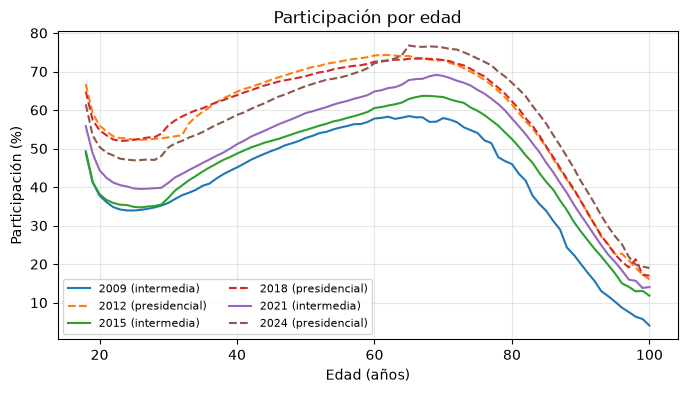

Edad (2021),Hombres (%),Mujeres (%),Diferencia mujeres − hombres (pp)
str,f64,f64,f64
"""18 a 19""",48.2,55.0,6.9
"""20 a 29""",35.7,45.7,10.0
"""30 a 39""",39.8,51.2,11.4
"""40 a 49""",49.9,59.5,9.7
"""50 a 59""",58.1,64.4,6.4
"""60 a 69""",66.1,67.4,1.2
"""70 a 79""",68.1,63.8,-4.2
"""80 a 89""",50.7,41.2,-9.4


In [17]:
por_edad = (
    datos.filter(pl.col('EDAD') <= 100).group_by('AELEC', 'EDAD').agg(pl.col('SV', 'NV').sum())
    .with_columns(p=pl.col('SV') / (pl.col('SV') + pl.col('NV')) * 100).sort('AELEC', 'EDAD').collect()
)
fig, ax = plt.subplots(figsize=(8, 4))
for anio in ANIOS:
    d = por_edad.filter(pl.col('AELEC') == anio)
    ax.plot(d['EDAD'], d['p'], label=f'{anio} ({TIPO[anio]})', linestyle='-' if TIPO[anio] == 'intermedia' else '--')
ax.set_xlabel('Edad (años)')
ax.set_ylabel('Participación (%)')
ax.set_title('Participación por edad')
ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.3)
plt.show()

(
    datos.filter((pl.col('AELEC') == 2021) & (pl.col('SEXO') < 2))
    .with_columns(decada=(pl.col('EDAD') // 10 * 10).clip(upper_bound=80))
    .group_by('decada', 'SEXO').agg(pl.col('SV', 'NV').sum()).collect()
    .with_columns(p=pl.col('SV') / (pl.col('SV') + pl.col('NV')) * 100)
    .pivot(on='SEXO', index='decada', values='p').sort('decada')
    .select(
        pl.format('{} a {}', pl.col('decada').clip(lower_bound=18), pl.col('decada') + 9).alias('Edad (2021)'),
        pl.col('0').round(1).alias('Hombres (%)'),
        pl.col('1').round(1).alias('Mujeres (%)'),
        (pl.col('1') - pl.col('0')).round(1).alias('Diferencia mujeres − hombres (pp)'),
    )
)

**Qué vemos:**

- **La participación por edad tiene forma de U:**
  - Empieza relativamente alta a los 18 años.
  - Baja hasta su mínimo entre los 23 y los 26 años.
  - Sube hasta su máximo entre los 61 y los 69.
  - Pasa en las seis elecciones.
- **Las mujeres votan más que los hombres** hasta los 69 años, con diferencias de hasta 11.4 pp en sus 30. A partir de los 70 se invierte.
- **El grupo que menos vota son los hombres de 20 a 29 años:** 35.7 % en 2021.

**Qué significa para la intervención:** el grupo objetivo más claro son **los jóvenes de 20 a 29, sobre todo hombres**, más que "de 18 a 34".

**Cuidado:** en la lista hay pocos jóvenes de 18 años. Los que se registraron a tiempo podrían ser los más motivados, y eso explicaría por qué votan más. Es una hipótesis.

### Rural contra urbano

In [18]:
datos.group_by('AELEC', 'TIPOSEC').agg(pl.col('SV', 'NV').sum()).with_columns(
    p=(pl.col('SV') / (pl.col('SV') + pl.col('NV')) * 100).round(1)
).collect().pivot(on='TIPOSEC', index='AELEC', values='p').sort('AELEC').select(
    pl.col('AELEC').alias('Elección'),
    pl.col('AELEC').replace_strict(TIPO, return_dtype=pl.String).alias('Tipo'),
    pl.col('U').alias('Urbana (%)'), pl.col('M').alias('Mixta (%)'), pl.col('R').alias('Rural (%)'),
    (pl.col('R') - pl.col('U')).round(1).alias('Rural − urbana (pp)'),
)

Elección,Tipo,Urbana (%),Mixta (%),Rural (%),Rural − urbana (pp)
i16,str,f64,f64,f64,f64
2009,"""intermedia""",42.8,44.6,48.1,5.3
2012,"""presidencial""",61.7,61.4,64.2,2.5
2015,"""intermedia""",44.9,48.4,54.5,9.6
2018,"""presidencial""",62.0,61.4,64.7,2.7
2021,"""intermedia""",50.1,52.2,58.4,8.3
2024,"""presidencial""",59.9,57.9,60.1,0.2


**Qué vemos:** lo rural vota más que lo urbano en todas las elecciones, pero la diferencia es mucho mayor en las intermedias (de 5 a 10 pp) que en las presidenciales (de 0 a 3 pp).

**Qué significa:** como **2027 es intermedia**, el porcentaje rural de cada municipio puede ser una variable útil para el modelo.

## 7 · Decisiones

**Decididas por Sofía Ordaz el 19 de octubre de 2026:** se adoptan todas las recomendaciones. Quedan registradas en `docs/bitacora.md`.

| # | Qué se decidió | Decisión | Por qué |
|---|---|---|---|
| D1 | Cómo calcular la participación | Votó / (Votó + No votó), igual que el INE | Es la oficial y no castiga a los municipios por papeles perdidos |
| D2 | Cuándo un año de un municipio es "sin dato" | Cuando no sabemos lo de más de la mitad de la lista, **o** cuando su lista es menor al 80 % de la de sus elecciones vecinas | La segunda regla atrapa el problema escondido de 2012 |
| D3 | Qué hacer con los municipios sin dato | "Sin dato" en ese año. Si se repite en varias elecciones, una marca propia en el mapa | La falta repetida (Cherán) puede ser parte del problema |
| D4 | Personas de 100 años o más | No quitarlas de los totales; agruparlas en "100 y más" en las gráficas por edad | Mueven a un municipio como máximo 0.39 pp en 2024 (1.9 pp en 2009) |
| D5 | Participación casi cero o sospechosamente alta | Casi cero → "sin dato". Altos que no encajan con su historia → marcar y probar el modelo con y sin ellos | Los ceros son errores; Guerrero 2024 es sospechoso; Yucatán es real |
| D6 | Historia de los municipios | Armarla con el territorio de 2024, sumando secciones | Resuelve los municipios nuevos, los que cedieron territorio y Paracho/Parácuaro |
| D7 | Sexo no binario (105 personas en 2024) | Incluirlas en los totales | Son muy pocas para un análisis aparte |
| D8 | Grupos de edad | Los del INE (quinquenios y "100 y más"), destacando el grupo de 20 a 29 | Comparables con la plataforma del INE; ahí está el grupo que menos vota |

## Lo que se declara como limitación en el reporte

- **No son los resultados oficiales:** no incluyen casillas especiales ni voto desde el extranjero.
- **Cuando no sabemos lo que hizo alguien, suponemos que votó igual que sus vecinos con dato.**
- **En 2012 faltan partes de la lista sin aviso.**
- **No conocemos las causas** de los municipios sin dato, de las edades extremas ni de los altos de Guerrero.